# 12 — XGBoost quantile regression

*Extension: min / max price · code: `src/sp500/range_models.py`, `run_range_models.py`*

Gradient-boosted trees with XGBoost's `reg:quantileerror` objective: one model per target outputs the 10%, 50% and 90% quantiles at once (400 trees, depth 4, learning rate 0.03, row / column subsampling).

← previous: [`11_range_features_targets.ipynb`](11_range_features_targets.ipynb) · next: [`13_catboost.ipynb`](13_catboost.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
import run_range_models as rrm
from sp500.config import DATA_PROCESSED
from sp500.range_data import load_range_table, feature_columns
from sp500.range_models import MODEL_NAMES
from sp500.plots import band_vs_actual, C_MAX, C_MIN

MODEL = "xgboost"
table = load_range_table()          # built in notebook 11
feats = feature_columns(table)
print(len(table), "rows,", len(feats), "features")

16186 rows, 72 features


## 1. Walk-forward 2000–2021 and holdout 2022+

Retrained every 2 years on all earlier data (with a 21 + *h* day gap so no training target overlaps the test block), then one model trained on data before 2022 is tested on 2022 → today. The volatility-band baseline is run alongside for reference.

In [3]:
pred = rrm.run_validation(table, feats, ["vol_band", MODEL], log=lambda *a: None)
pred[pred.model == MODEL].to_parquet(DATA_PROCESSED / f"range_pred_{MODEL}.parquet")
print(f"{(pred.model == MODEL).sum():,} out-of-sample predictions saved")

26,972 out-of-sample predictions saved


## 2. Scores

- **MAE %**: error of the median forecast, in % of price.
- **Pinball ×100**: quantile loss of the whole 10/50/90% band (lower is better).
- **Coverage 80%**: share of days inside the 10–90% band (ideal 0.80).
- **Skill**: 1 − MAE / MAE of the volatility band (> 0 beats it).

In [4]:
m = rrm.metrics(pred)
m["target"] = m["target"].map({"up": "max high", "down": "min low"})
show = m.pivot_table(index=["split", "h", "target"], columns="model",
                     values=["mae_pct", "pinball_x100", "coverage_80", "mae_skill_vs_volband"])
show.style.format("{:.3f}")

## 3. Forecast vs. reality on the holdout

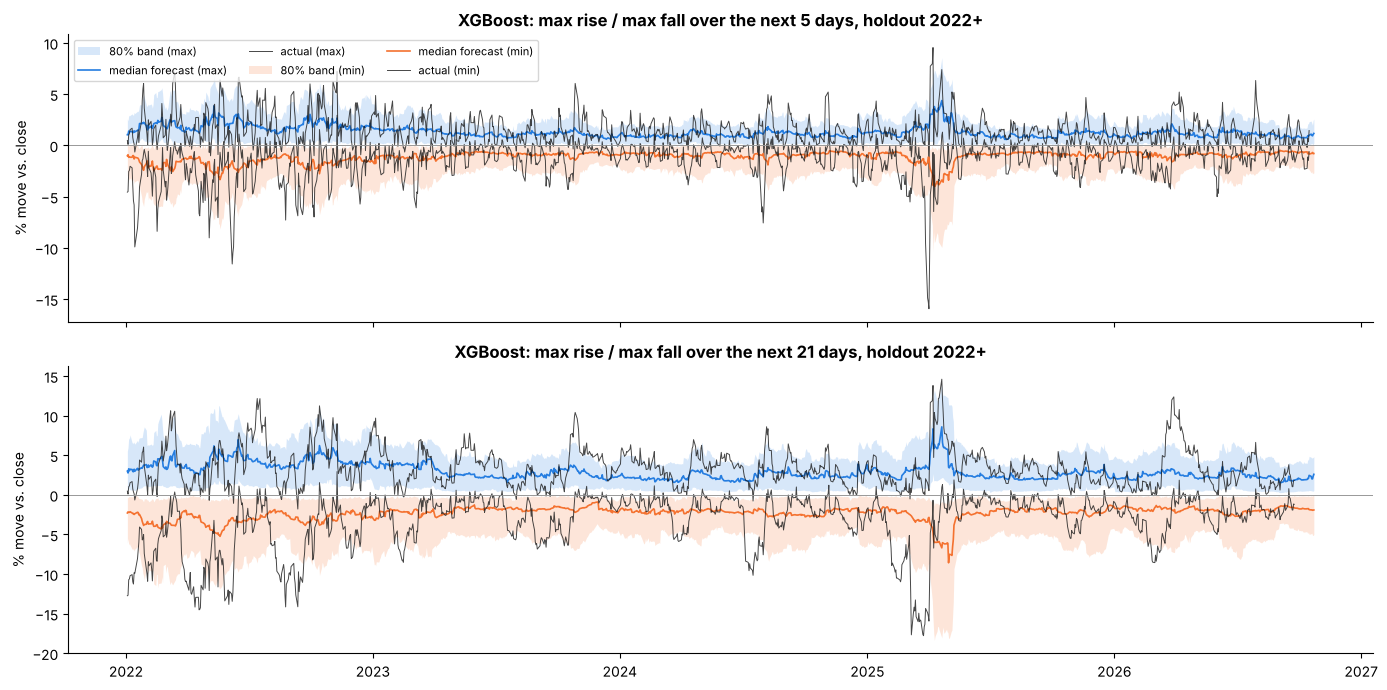

In [5]:
h_pred = pred[(pred.model == MODEL) & (pred.split == "holdout")]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, h in zip(axes, (5, 21)):
    for t, col, lab in (("up", C_MAX, "max"), ("down", C_MIN, "min")):
        band_vs_actual(ax, h_pred[(h_pred.h == h) & (h_pred.target == t)], col, lab)
    ax.set_title(f"{MODEL_NAMES[MODEL]}: max rise / max fall over the next {h} days, holdout 2022+")
axes[0].legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

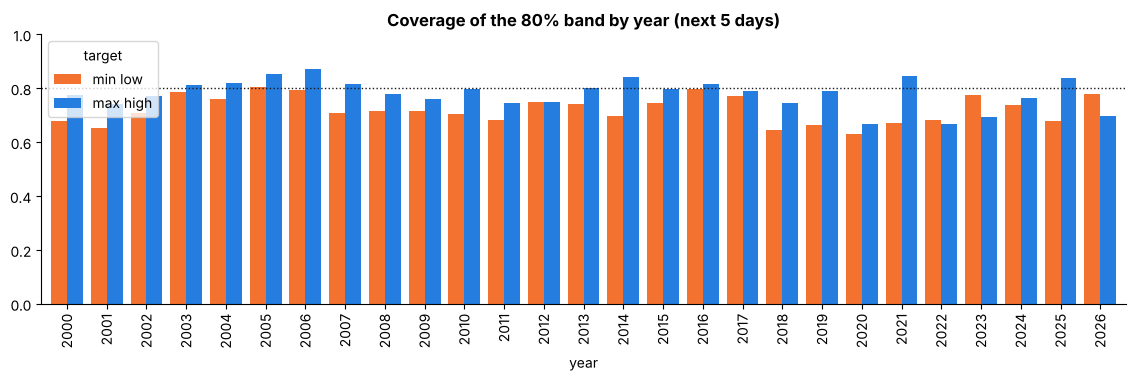

In [6]:
g = pred[(pred.model == MODEL)].dropna(subset=["actual"])
g = g.assign(year=g.date.dt.year, inside=(g.actual >= g.q10) & (g.actual <= g.q90))
cov = g[g.h == 5].pivot_table(index="year", columns="target", values="inside")
ax = cov.rename(columns={"up": "max high", "down": "min low"}).plot.bar(figsize=(14, 3.5), color=[C_MIN, C_MAX], width=0.8)
ax.axhline(0.8, color="#191919", ls=":", lw=1); ax.set_ylim(0, 1)
ax.set_title("Coverage of the 80% band by year (next 5 days)"); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. What the model uses

Feature importance of a model trained on all data (both horizons, max and min averaged).

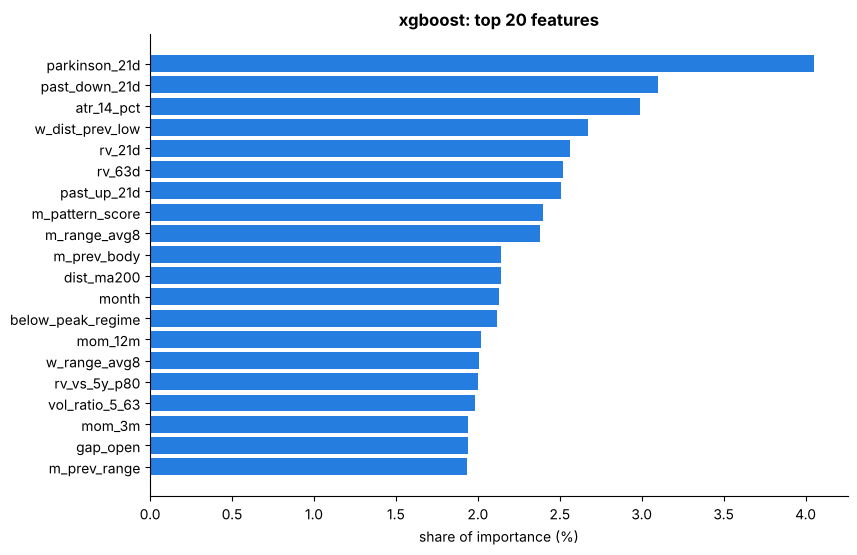

In [7]:
from sp500.range_models import MODELS
imps = []
for h in (5, 21):
    for t in ("up", "down"):
        y = table[f"{t}_{h}"] / table[f"sigma_{h}"]
        ok = y.notna() & table[f"sigma_{h}"].notna()
        mdl = MODELS["xgboost"]().fit(table.loc[ok, feats], y[ok])
        imp = mdl.importance(feats)
        imps.append(imp / imp.sum())
imp = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)
top = imp.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values * 100, color="#257de0")
ax.set_xlabel("share of importance (%)"); ax.set_title("xgboost: top 20 features")
ax.spines[["top", "right"]].set_visible(False); plt.show()

**Result.** XGBoost beats the volatility band on the next-week max and min, in walk-forward and on the holdout (≈ +5% MAE skill for the max). For the next-month min it does not. Volatility and range features dominate; weekly / monthly candle features come right after.